# 04 · Evaluasi dan jawaban pertanyaan penelitian

**Tujuan:** menghitung Macro-F1, balanced accuracy, matriks kebingungan, lalu perubahan berpasangan **K2 − K1** (tambahan teknikal) dan **K3 − K2** (tambahan makro).

**Input:** `output/03_prediksi.parquet`
**Padanan kode penelitian:** `evaluation.py` (`score`, `_paired`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score

OUTPUT = Path("output")
pred = pd.read_parquet(OUTPUT / "03_prediksi.parquet")
NAMA_MODEL = {"logistic_regression": "Regresi Logistik", "xgboost": "XGBoost"}

## 1. Skor per periode

- **Macro-F1** (metrik utama): rata-rata F1 BUY, HOLD, SELL dengan bobot sama.
- **Balanced accuracy:** rata-rata recall ketiga kelas.

In [2]:
def skor(g):
    return pd.Series({
        "bar_uji": len(g),
        "macro_f1": f1_score(g["benar"], g["prediksi"], labels=["SELL", "HOLD", "BUY"], average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(g["benar"], g["prediksi"]),
    })

hasil = pred.groupby(["model", "konfigurasi", "periode"], sort=False).apply(skor).reset_index()
tabel = hasil.pivot_table(index="periode", columns=["model", "konfigurasi"], values="macro_f1", sort=False)
tabel.round(4)

model        logistic_regression                 xgboost                
konfigurasi                   K1      K2      K3      K1      K2      K3
periode                                                                 
2023-H1                   0.4238  0.4236  0.4133  0.4246  0.4133  0.4276
2023-H2                   0.3912  0.3924  0.3893  0.3930  0.3847  0.3881
2024-H1                   0.3950  0.3987  0.3951  0.3929  0.4007  0.3941
2024-H2                   0.3891  0.3883  0.3871  0.3874  0.4004  0.3920
2025-H1                   0.3912  0.3872  0.3895  0.3895  0.3869  0.3919
2025-H2                   0.3795  0.3784  0.3824  0.3765  0.3827  0.3795
2026-Jan-Jul              0.3762  0.3780  0.3798  0.3672  0.3856  0.3834

## 2. Rerata tujuh periode dan perubahan berpasangan

In [3]:
baris = []
for model, nama_model in NAMA_MODEL.items():
    t = tabel[model]
    for nama, kiri, kanan in (("K2 − K1 (teknikal)", "K1", "K2"), ("K3 − K2 (makro)", "K2", "K3")):
        d = t[kanan] - t[kiri]
        baris.append({"model": nama_model, "perubahan": nama, "rerata": d.mean(), "median": d.median(),
                      "simpangan_baku": d.std(), "periode_positif": f"{(d > 0).sum()} / {len(d)}"})

rerata = tabel.mean().unstack().rename(index=NAMA_MODEL)
display(rerata.round(6))
pd.DataFrame(baris).round(6)

konfigurasi,K1,K2,K3
model,,,
Regresi Logistik,0.392300,0.392374,0.390922
XGBoost,0.390178,0.393466,0.393791


,model,perubahan,rerata,median,simpangan_baku,periode_positif
0,Regresi Logistik,K2 − K1 (teknikal),0.000074,-0.000237,0.002452,3 / 7
1,Regresi Logistik,K3 − K2 (makro),-0.001452,-0.001243,0.004821,3 / 7
2,XGBoost,K2 − K1 (teknikal),0.003289,0.006163,0.011031,4 / 7
3,XGBoost,K3 − K2 (makro),0.000324,-0.002231,0.007837,3 / 7


## 3. Grafik Macro-F1 per periode

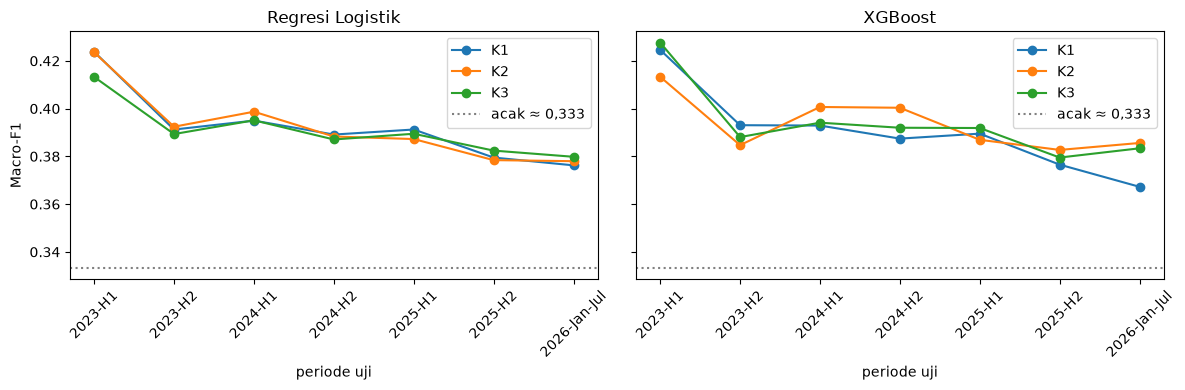

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model in zip(axes, NAMA_MODEL):
    tabel[model].plot(ax=ax, marker="o")
    ax.axhline(1 / 3, ls=":", c="gray", label="acak ≈ 0,333")
    ax.set_title(NAMA_MODEL[model])
    ax.set_xlabel("periode uji")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
axes[0].set_ylabel("Macro-F1")
plt.tight_layout()

## 4. Matriks kebingungan gabungan tujuh periode (urutan BUY, HOLD, SELL)

Baris = label benar, kolom = prediksi.

In [5]:
urutan = ["BUY", "HOLD", "SELL"]
for model, nama_model in NAMA_MODEL.items():
    g = pred[(pred["model"] == model) & (pred["konfigurasi"] == "K2")]
    cm = pd.DataFrame(confusion_matrix(g["benar"], g["prediksi"], labels=urutan), index=urutan, columns=urutan)
    print(nama_model, "· K2")
    display(cm)

Regresi Logistik · K2


,BUY,HOLD,SELL
BUY,1465,2368,1568
HOLD,1697,5769,2128
SELL,1285,2092,1526


XGBoost · K2


,BUY,HOLD,SELL
BUY,1676,1982,1743
HOLD,2129,5035,2430
SELL,1395,1761,1747


## 5. Cocokkan dengan hasil resmi penelitian

Jika notebook ini benar mengikuti kode penelitian, skornya harus sama dengan run `metaquotes-demo-primary-0p5-k3`.

In [6]:
# lokasi hasil resmi: folder P1 lokal atau repo GitHub P1
lokal = Path("../../05_Hasil/Metrik_Utama_MetaQuotes_0p5.csv")
repo = Path("../../05_hasil/metrik-per-fold.csv")
if lokal.exists():
    resmi = pd.read_csv(lokal).rename(columns={"periode_uji": "periode"})
elif repo.exists():
    resmi = pd.read_csv(repo)
    resmi = resmi[resmi["run"] == "metaquotes-demo-primary-0p5-k3"].rename(
        columns={"fold": "periode", "configuration": "konfigurasi"})
else:
    resmi = None
    print("File hasil resmi tidak ditemukan")

if resmi is not None:
    banding = hasil.merge(resmi[["periode", "model", "konfigurasi", "macro_f1"]],
                          on=["periode", "model", "konfigurasi"], suffixes=("_notebook", "_resmi"))
    banding["selisih"] = (banding["macro_f1_notebook"] - banding["macro_f1_resmi"]).abs()
    print("Pasangan dibandingkan:", len(banding), "· selisih terbesar:", banding["selisih"].max())

Pasangan dibandingkan: 42 · selisih terbesar: 5.551115123125783e-17


## 6. Cara membaca

- Perubahan Macro-F1 dari menambah fitur teknikal dan makro **sangat kecil** dan arahnya **tidak konsisten** antarperiode maupun antarmodel.
- Selisih mencakup efek penyetelan ulang hiperparameter, bukan pengaruh murni fitur.
- K3 berlaku untuk snapshot kalender retrospektif.
- Tidak ada klaim keuntungan transaksi atau hubungan kausal.

Tidak ada di notebook ini (tetap di kode penelitian dan Bab 4): sensitivitas ambang 0,25/1,0, policy holiday-reset, sumber Ultima, analisis hiperparameter tetap, dan diagnostik kelas mayoritas.